In [3]:
import json
import random
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt


torch.manual_seed(0)
random.seed(0)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("Using device:", device)

Using device: cuda


In [4]:
from sklearn.model_selection import train_test_split

images_path = Path("dataset/images")
data = json.loads(Path("dataset/gt_public.json").read_text())

image_ids = list(data.keys())
train_ids, rest_ids = train_test_split(image_ids, test_size=0.2, random_state=0)
val_ids, test_ids = train_test_split(rest_ids, test_size=0.5, random_state=0)

print(f"Train: {len(train_ids)}, Val: {len(val_ids)}, Test: {len(test_ids)}")


Train: 41470, Val: 5184, Test: 5184


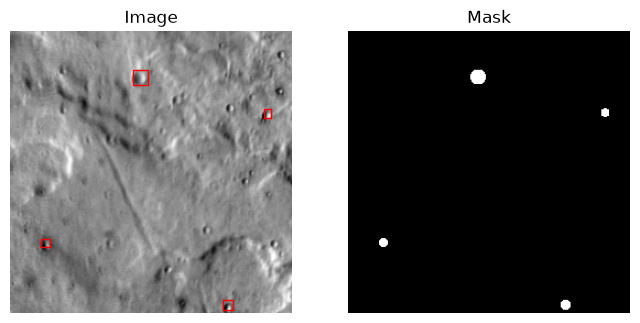

In [5]:
from matplotlib.patches import Rectangle


def make_mask(boxes):
    mask = np.zeros((256, 256), dtype=np.uint8)
    yy, xx = np.mgrid[0:256, 0:256]

    for x, y, w, h in boxes:
        cx = x + w / 2
        cy = y + h / 2
        r = max(w, h) / 2
        inside = (xx + 0.5 - cx) ** 2 + (yy + 0.5 - cy) ** 2 <= r ** 2
        mask[inside] = 1

    return mask


image_id = train_ids[0]
image = plt.imread(images_path / f"{image_id}.png")
mask = make_mask(data[image_id])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))

ax1.imshow(image, cmap="gray")
for x, y, w, h in data[image_id]:
    ax1.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor="red", linewidth=1))
ax1.set_title("Image")
ax1.axis("off")

ax2.imshow(mask, cmap="gray")
ax2.set_title("Mask")
ax2.axis("off")

plt.show()

In [6]:
class CraterDataset(Dataset):
    def __init__(self, image_ids):
        self.image_ids = image_ids

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, i):
        image_id = self.image_ids[i]

        image = Image.open(images_path / f"{image_id}.png").convert("L")
        image = torch.tensor(np.array(image), dtype=torch.float32) / 255.0
        image = image.unsqueeze(0)

        mask = make_mask(data[image_id])
        mask = torch.tensor(mask, dtype=torch.float32).unsqueeze(0)

        return image, mask


train_set = CraterDataset(train_ids)
val_set = CraterDataset(val_ids)
test_set = CraterDataset(test_ids)

train_loader = DataLoader(train_set, batch_size=16, shuffle=True)
val_loader = DataLoader(val_set, batch_size=16, shuffle=False)
test_loader = DataLoader(test_set, batch_size=16, shuffle=False)

images, masks = next(iter(train_loader))
print(images.shape)
print(masks.shape)

torch.Size([16, 1, 256, 256])
torch.Size([16, 1, 256, 256])


In [7]:
def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        nn.ReLU(),
    )


class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.pool = nn.MaxPool2d(2)

        # shrinking half
        self.down1 = conv_block(1, 32)      # (32, 256, 256)
        self.down2 = conv_block(32, 64)     # (64, 128, 128)
        self.down3 = conv_block(64, 128)    # (128, 64, 64)
        self.bottom = conv_block(128, 256)  # (256, 32, 32)

        # growing half
        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)  # (128, 64, 64)
        self.conv3 = conv_block(256, 128)
        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)   # (64, 128, 128)
        self.conv2 = conv_block(128, 64)
        self.up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)    # (32, 256, 256)
        self.conv1 = conv_block(64, 32)

        self.out = nn.Conv2d(32, 1, kernel_size=1)  # (1, 256, 256)

    def forward(self, x):
        d1 = self.down1(x)
        d2 = self.down2(self.pool(d1))
        d3 = self.down3(self.pool(d2))
        b = self.bottom(self.pool(d3))

        u3 = self.conv3(torch.cat([self.up3(b), d3], dim=1))
        u2 = self.conv2(torch.cat([self.up2(u3), d2], dim=1))
        u1 = self.conv1(torch.cat([self.up1(u2), d1], dim=1))
        return self.out(u1)

model = UNet().to(device)
print(sum(p.numel() for p in model.parameters()))

with torch.no_grad():
    out = model(images.to(device))
print(out.shape)

1925025
torch.Size([16, 1, 256, 256])


In [8]:
import time

model = UNet().to(device)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([10.0], device=device))
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


def evaluate(model, loader):
    model.eval()
    total_loss, intersection, union, n = 0.0, 0, 0, 0

    with torch.no_grad():
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)

            outputs = model(images)
            total_loss += loss_fn(outputs, masks).item() * len(images)

            preds = (outputs > 0).float()
            intersection += (preds * masks).sum().item()
            union += ((preds + masks) > 0).sum().item()
            n += len(images)

    return total_loss / n, intersection / union

In [14]:
train_loader = DataLoader(train_set, batch_size=16, shuffle=True)
print(len(train_loader.dataset))

model = UNet().to(device)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([10.0], device=device))
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

41470


In [18]:
from tqdm import tqdm

epochs = 10
history = {"train_loss": [], "val_loss": [], "val_iou": []}

for epoch in range(epochs):
    model.train()
    running_loss, n = 0.0, 0
    start = time.time()

    progress = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{epochs}")
    for images, masks in progress:
        images, masks = images.to(device), masks.to(device)

        outputs = model(images)
        loss = loss_fn(outputs, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(images)
        n += len(images)
        progress.set_postfix(loss=f"{running_loss / n:.4f}")

    train_loss = running_loss / n
    val_loss, val_iou = evaluate(model, val_loader)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_iou"].append(val_iou)
    torch.save(model.state_dict(), "unet.pt")

    print(f"Epoch {epoch + 1}: train loss {train_loss:.4f} | val loss {val_loss:.4f}, val IoU {val_iou:.4f} | {time.time() - start:.0f}s")

Epoch 1/10: 100%|██████████| 2592/2592 [04:12<00:00, 10.27it/s, loss=0.3728]


Epoch 1: train loss 0.3728 | val loss 0.3471, val IoU 0.1940 | 263s


Epoch 2/10: 100%|██████████| 2592/2592 [02:25<00:00, 17.78it/s, loss=0.3025]


Epoch 2: train loss 0.3025 | val loss 0.3021, val IoU 0.4019 | 157s


Epoch 3/10: 100%|██████████| 2592/2592 [02:25<00:00, 17.75it/s, loss=0.2784]


...

Epoch 8: train loss 0.2348 | val loss 0.2620, val IoU 0.3069 | 154s


Epoch 9/10: 100%|██████████| 2592/2592 [02:23<00:00, 18.03it/s, loss=0.2306]


Epoch 9: train loss 0.2306 | val loss 0.2633, val IoU 0.4495 | 154s


Epoch 10/10: 100%|██████████| 2592/2592 [02:24<00:00, 17.98it/s, loss=0.2243]


Epoch 10: train loss 0.2243 | val loss 0.2554, val IoU 0.3742 | 155s


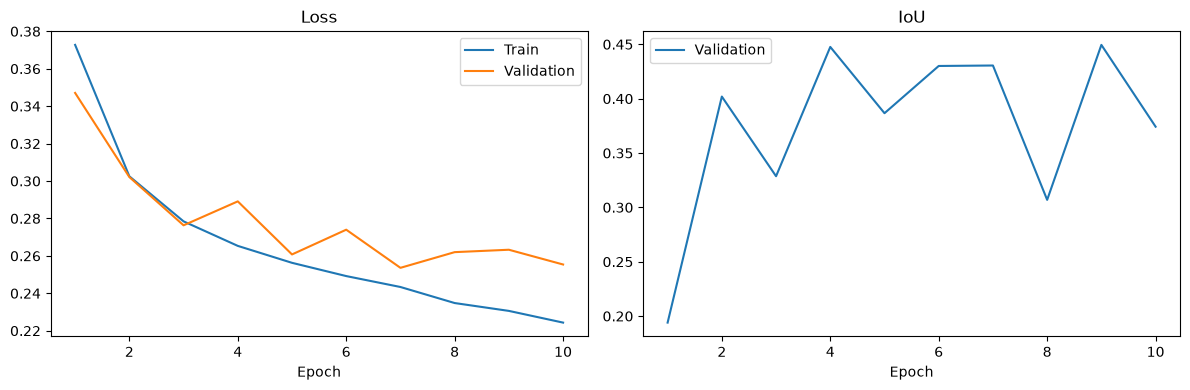

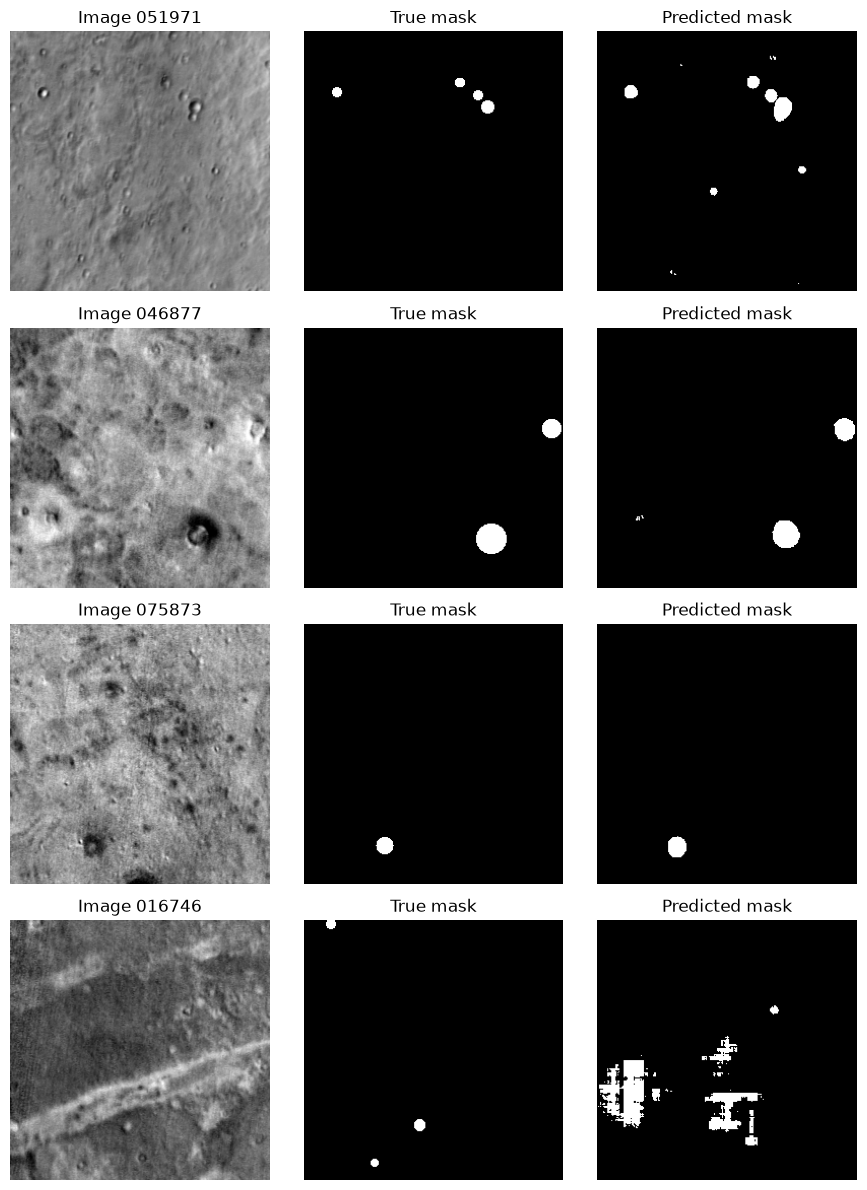

In [20]:
import shutil

run_name = "01-baseline-adam-lr1e-3-posweight10-10epochs"
run_dir = Path("src/unet") / run_name
run_dir.mkdir(parents=True, exist_ok=True)

# 1. Settings, history, and model
notes = """model: UNet (32-64-128-256 channels), 1,925,025 parameters
loss: BCEWithLogitsLoss, pos_weight=10
optimizer: Adam, lr=1e-3, no weight decay
batch size: 16
epochs: 10
"""
(run_dir / "notes.txt").write_text(notes)
(run_dir / "history.json").write_text(json.dumps(history))
shutil.copy("unet.pt", run_dir / "unet.pt")

# 2. Loss and IoU curves
epochs_range = range(1, len(history["train_loss"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs_range, history["train_loss"], label="Train")
ax1.plot(epochs_range, history["val_loss"], label="Validation")
ax1.set_title("Loss")
ax1.set_xlabel("Epoch")
ax1.legend()

ax2.plot(epochs_range, history["val_iou"], label="Validation")
ax2.set_title("IoU")
ax2.set_xlabel("Epoch")
ax2.legend()

plt.tight_layout()
plt.savefig(run_dir / "curves.png", dpi=150, bbox_inches="tight")
plt.show()

# 3. Example predictions: image, true mask, predicted mask
model.eval()
fig, axes = plt.subplots(4, 3, figsize=(9, 12))

for i, row in enumerate(axes):
    image, mask = val_set[i]
    with torch.no_grad():
        pred = model(image.unsqueeze(0).to(device))
    pred = (pred > 0).float().squeeze().cpu()

    row[0].imshow(image.squeeze(), cmap="gray")
    row[0].set_title(f"Image {val_ids[i]}")
    row[1].imshow(mask.squeeze(), cmap="gray")
    row[1].set_title("True mask")
    row[2].imshow(pred, cmap="gray")
    row[2].set_title("Predicted mask")
    for ax in row:
        ax.axis("off")

plt.tight_layout()
plt.savefig(run_dir / "predictions.png", dpi=150, bbox_inches="tight")
plt.show()